# Intake Regime Change

Phân tích điểm gãy của hệ thống tiếp nhận 311 (bộ phân loại yêu cầu đổi giữa ngày 11 và 13/6/2024) để trả lời:
- **RQ1:** điểm gãy tháng 6/2024 làm thay đổi dữ liệu đến mức nào — về tổng số yêu cầu, về cơ cấu loại yêu cầu và giữa các khu phố?
- **RQ3:** chuẩn bị cho đánh giá độ bền của mô hình — xác định mốc kiểm tra nào nằm trước, chứa hoặc nằm sau điểm gãy.

**Dữ liệu đầu vào** (từ Notebook 2):
- `SF_311_Tree_Cases_Cleaned.csv`: từng yêu cầu, có loại yêu cầu đã chuẩn hoá (`loai_yeu_cau`) và cờ yêu cầu trùng (`la_trung`).
- `SF_Tree_Weekly_Data_Cleaned.csv`: bảng khu phố × tuần.

Trừ mục 5, mọi phân tích dùng các yêu cầu **không trùng**, khớp với biến mục tiêu chính `n`.

## **1. Khởi tạo và nạp dữ liệu**

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

import warnings
warnings.filterwarnings("ignore")
sns.set_style("ticks")
os.makedirs("../Outputs/figures", exist_ok=True)
os.makedirs("../Outputs/tables", exist_ok=True)

NGAY_DOI_HE_THONG = pd.Timestamp("2024-06-12")   # bộ phân loại 311 đổi giữa ngày 11 và 13/6/2024
TUAN_DOI = pd.Timestamp("2024-06-10")            # Thứ Hai của tuần có ngày đổi hệ thống

# Năm loại yêu cầu đã chuẩn hoá ở Notebook 2 và tên tiếng Việt dùng trên biểu đồ
LOAI = ["damaged_tree", "overgrown_tree", "damaging_property", "landscaping", "other"]
TEN_LOAI = {
    "damaged_tree": "Cây hư hại",
    "overgrown_tree": "Cây mọc rậm",
    "damaging_property": "Cây gây hư hại tài sản",
    "landscaping": "Cảnh quan",
    "other": "Khác",
}
MAU_LOAI = dict(zip(LOAI, sns.color_palette("tab10", 5)))

cases_all = pd.read_csv("../Data/processed/SF_311_Tree_Cases_Cleaned.csv", parse_dates=["date", "week_start"])
weekly = pd.read_csv("../Data/processed/SF_Tree_Weekly_Data_Cleaned.csv", parse_dates=["week_start"])
cases = cases_all[~cases_all["la_trung"]].copy()   # chỉ giữ yêu cầu không trùng

print(f"Số yêu cầu (giữ cả trùng) : {len(cases_all):,}")
print(f"Số yêu cầu (đã loại trùng): {len(cases):,}")
print(f"Bảng tuần                 : {weekly.shape}")

Số yêu cầu (giữ cả trùng) : 132,196
Số yêu cầu (đã loại trùng): 116,057
Bảng tuần                 : (25174, 15)


In [2]:
# Số yêu cầu mỗi tuần của toàn thành phố, tách theo loại (đủ 614 tuần, tuần không có yêu cầu = 0)
weeks = pd.DatetimeIndex(sorted(weekly["week_start"].unique()))
city_type = (cases.groupby(["week_start", "loai_yeu_cau"]).size()
             .unstack(fill_value=0).reindex(index=weeks, columns=LOAI, fill_value=0))
city_type["tong"] = city_type[LOAI].sum(axis=1)

# Kiểm tra: tổng theo loại phải bằng tổng biến n của bảng tuần
print("Tổng theo loại :", f"{int(city_type['tong'].sum()):,}")
print("Tổng biến n    :", f"{int(weekly['n'].sum()):,}")
city_type.tail()

Tổng theo loại : 116,057
Tổng biến n    : 116,057


loai_yeu_cau,damaged_tree,overgrown_tree,damaging_property,landscaping,other,tong
2026-09-07,91,99,36,42,4,272
2026-09-14,84,92,61,55,4,296
2026-09-21,92,120,43,86,3,344
2026-09-28,101,106,36,83,2,328
2026-10-05,113,92,55,76,7,343


## **2. Diễn biến từng loại yêu cầu theo quý**

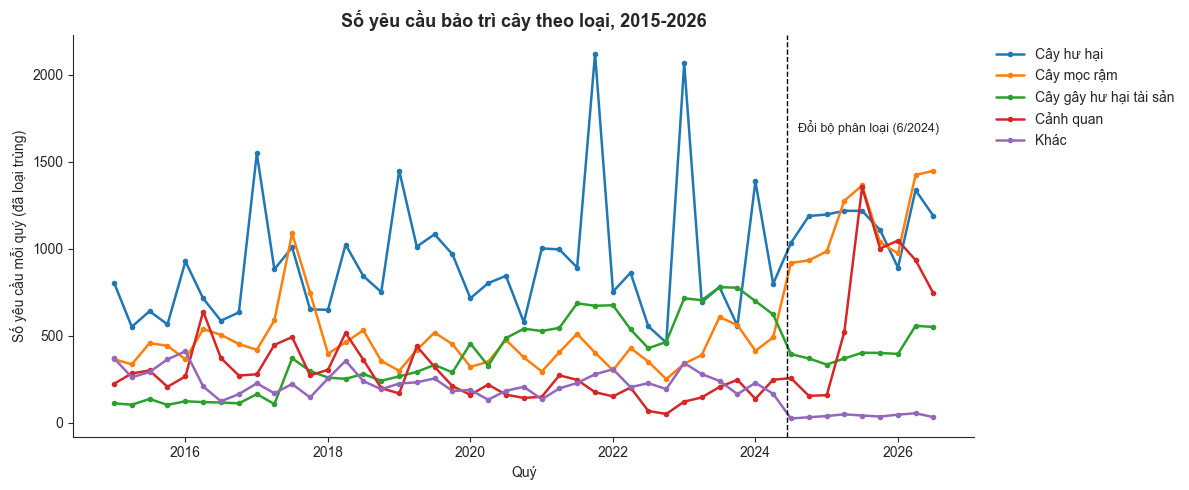

loai_yeu_cau,damaged_tree,overgrown_tree,damaging_property,landscaping,other
date,,,,,
2023Q1,2066,340,716,122,344
2023Q2,694,390,705,146,280
2023Q3,780,608,780,206,241
2023Q4,558,562,777,247,165
2024Q1,1388,414,700,138,230
2024Q2,799,491,623,248,167
2024Q3,1034,919,395,257,25
2024Q4,1189,934,370,155,32
2025Q1,1198,986,335,159,39


In [3]:
# Số yêu cầu mỗi quý theo loại (bỏ quý cuối 2026 vì mới có vài tuần)
quy = cases.groupby([cases["date"].dt.to_period("Q"), "loai_yeu_cau"]).size().unstack(fill_value=0)[LOAI]
quy = quy.loc[: "2026Q3"]
quy_moc = quy.index.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 5))
for loai in LOAI:
    ax.plot(quy_moc, quy[loai], marker="o", markersize=3, linewidth=1.8, color=MAU_LOAI[loai], label=TEN_LOAI[loai])
ax.axvline(NGAY_DOI_HE_THONG, color="black", linestyle="--", linewidth=1)
ax.annotate("Đổi bộ phân loại (6/2024)", (NGAY_DOI_HE_THONG, quy.values.max() * 0.8),
            textcoords="offset points", xytext=(8, 0), ha="left", va="center", fontsize=9)
sns.despine()
ax.set_xlabel("Quý")
ax.set_ylabel("Số yêu cầu mỗi quý (đã loại trùng)")
ax.set_title("Số yêu cầu bảo trì cây theo loại, 2015-2026", fontsize=13, fontweight="bold")
ax.legend(frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig("../Outputs/figures/fig_r01_quarterly_by_type.png", dpi=300)
plt.show()

quy.loc["2023Q1":]

**Nhận xét:** Diễn biến từng loại yêu cầu theo quý

**Vì sao dùng biểu đồ này?** Tổng số yêu cầu có thể che mất việc các loại yêu cầu "chuyển chỗ" cho nhau. Vẽ riêng từng loại theo quý, kèm đường đánh dấu ngày đổi hệ thống, cho thấy loại nào thay đổi và thay đổi vào lúc nào.

**Kết quả cần đọc:**
- **Ngay tại điểm gãy (quý 3/2024)**, ba loại đổi hướng cùng lúc: **"Khác" gần như biến mất** (167 → 25 yêu cầu/quý), **"Cây gây hư hại tài sản" giảm khoảng 37%** (623 → 395), còn **"Cây mọc rậm" gần gấp đôi** (491 → 919).
- **"Cây hư hại"** dao động theo bão như trước (quý 1/2023 vọt lên 2,066), và sau điểm gãy giữ ở mức khá ổn định (khoảng 1,000–1,300 yêu cầu/quý).
- **"Cảnh quan"** không đổi tại điểm gãy, nhưng **tăng vọt từ quý 2/2025** (159 → 523 → 1,355 yêu cầu/quý) — gần một năm sau khi đổi hệ thống.
- → Điểm gãy tháng 6/2024 chủ yếu là **sự chuyển dịch giữa các loại yêu cầu** (cùng một vấn đề được xếp vào loại khác); mức tăng của "Cảnh quan" từ 2025 là **một thay đổi riêng, xảy ra sau**.

## **3. So sánh năm trước và năm sau điểm gãy**

Mỗi "năm" là **52 tuần liên tiếp**, căn theo tuần đổi hệ thống (bắt đầu từ tuần 10/06 mỗi năm), nên năm nào cũng chứa đủ các mùa và so sánh được với nhau. Thay đổi qua điểm gãy được đặt cạnh **các thay đổi năm-qua-năm bình thường** trước đó, để biết thay đổi nào là bất thường.

**Khoảng cách cơ cấu** giữa hai năm liền nhau = một nửa tổng chênh lệch tỷ trọng của 5 loại (đơn vị: điểm phần trăm). Giá trị này cho biết **bao nhiêu phần trăm số yêu cầu phải "đổi loại"** để cơ cấu năm trước giống năm sau: 0 là cơ cấu giống hệt, 100 là khác hoàn toàn.

In [4]:
# Trung bình số yêu cầu mỗi tuần (toàn thành phố) của từng năm 52 tuần, căn theo tuần đổi hệ thống
rows = []
k = 0
while True:
    bat_dau = TUAN_DOI - pd.Timedelta(weeks=52 * (9 - k))
    cua_so = city_type[(city_type.index >= bat_dau) & (city_type.index < bat_dau + pd.Timedelta(weeks=52))]
    if len(cua_so) < 52:
        break
    rows.append({"nam_bat_dau": bat_dau.date(), **cua_so.mean().round(2).to_dict()})
    k += 1
nam = pd.DataFrame(rows).set_index("nam_bat_dau")

# Thay đổi giữa hai năm liền nhau: tổng số yêu cầu (%) và khoảng cách cơ cấu (điểm %)
ty_trong = nam[LOAI].div(nam[LOAI].sum(axis=1), axis=0)
nam["thay_doi_tong_%"] = (nam["tong"].pct_change() * 100).round(1)
nam["khoang_cach_co_cau"] = (ty_trong.diff().abs().sum(axis=1) / 2 * 100).round(1)
nam.loc[nam.index[0], "khoang_cach_co_cau"] = np.nan
nam["giai_doan"] = np.where(pd.to_datetime(nam.index) < TUAN_DOI, "Trước điểm gãy", "Sau điểm gãy")
nam

,damaged_tree,overgrown_tree,damaging_property,landscaping,other,tong,thay_doi_tong_%,khoang_cach_co_cau,giai_doan
nam_bat_dau,,,,,,,,,
2015-06-22,54.15,34.04,9.13,26.31,24.42,148.06,NaN,NaN,Trước điểm gãy
2016-06-20,69.17,37.15,9.75,26.56,13.35,155.98,5.3,8.7,Trước điểm gãy
2017-06-19,64.08,52.50,22.50,30.37,18.38,187.83,20.4,11.1,Trước điểm gãy
2018-06-18,78.13,30.81,20.63,22.58,17.27,169.42,-9.8,12.6,Trước điểm gãy
2019-06-17,67.42,31.37,26.17,17.69,14.48,157.13,-7.3,6.3,Trước điểm gãy
2020-06-15,65.71,30.02,39.67,14.17,13.75,163.33,3.9,7.6,Trước điểm gãy
2021-06-14,89.90,30.73,50.02,15.15,19.96,205.77,26.0,4.8,Trước điểm gãy
2022-06-13,73.27,26.25,41.98,7.56,19.19,168.25,-18.2,3.0,Trước điểm gãy
2023-06-12,66.33,38.83,58.23,15.04,16.83,195.25,16.0,12.4,Trước điểm gãy


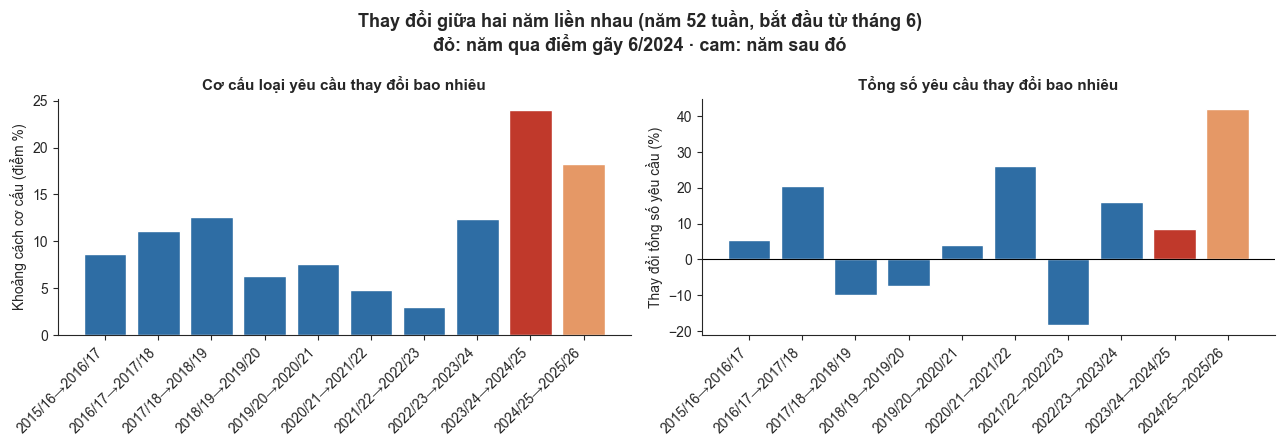

In [5]:
# Biểu đồ: khoảng cách cơ cấu và thay đổi tổng số yêu cầu giữa hai năm liền nhau
d = nam.dropna(subset=["khoang_cach_co_cau"]).copy()
nhan = [f"{pd.Timestamp(i).year - 1}/{str(pd.Timestamp(i).year)[2:]}→{pd.Timestamp(i).year}/{str(pd.Timestamp(i).year + 1)[2:]}"
        for i in d.index]
mau = ["#C0392B" if pd.Timestamp(i) == TUAN_DOI else ("#E59866" if pd.Timestamp(i) > TUAN_DOI else "#2E6DA4") for i in d.index]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(nhan, d["khoang_cach_co_cau"], color=mau)
axes[0].set_ylabel("Khoảng cách cơ cấu (điểm %)")
axes[0].set_title("Cơ cấu loại yêu cầu thay đổi bao nhiêu", fontsize=11, fontweight="bold")
axes[1].bar(nhan, d["thay_doi_tong_%"], color=mau)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("Thay đổi tổng số yêu cầu (%)")
axes[1].set_title("Tổng số yêu cầu thay đổi bao nhiêu", fontsize=11, fontweight="bold")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
    for t in ax.get_xticklabels():
        t.set_ha("right")
    sns.despine(ax=ax)
fig.suptitle("Thay đổi giữa hai năm liền nhau (năm 52 tuần, bắt đầu từ tháng 6)\nđỏ: năm qua điểm gãy 6/2024 · cam: năm sau đó",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../Outputs/figures/fig_r02_year_over_year_change.png", dpi=300)
plt.show()

**Nhận xét:** Năm trước và năm sau điểm gãy

**Vì sao làm bước này?** Một thay đổi chỉ đáng gọi là "điểm gãy" nếu nó **lớn hơn hẳn** các dao động năm-qua-năm thường thấy. Vì vậy thay đổi qua tháng 6/2024 được so với 8 lần thay đổi năm-qua-năm trước đó (2015–2024).

**Kết quả cần đọc:**
- **Cơ cấu thay đổi mạnh nhất trong 11 năm:** khoảng cách cơ cấu qua điểm gãy là **24.0 điểm %** — gần gấp đôi mức lớn nhất trước đó (**12.6**); các năm bình thường chỉ khoảng **3–13**.
- **Tổng số yêu cầu gần như không bị ảnh hưởng:** năm sau điểm gãy chỉ tăng **8.4%**, nằm trong dao động bình thường (từ **−18.2%** đến **+26.0%**).
- **Năm kế tiếp (từ tháng 6/2025)** mới tăng mạnh: **+41.9%**, lớn nhất trong 11 năm, đồng thời cơ cấu tiếp tục đổi (**18.2 điểm %**) — chủ yếu do loại **"Cảnh quan"** (từ khoảng 20 lên 83 yêu cầu/tuần).
- → Dữ liệu có **hai thay đổi nối tiếp nhau**: (1) tháng 6/2024 — **đổi cách phân loại**, tổng gần như giữ nguyên; (2) từ giữa 2025 — **tổng tăng mạnh**, tập trung ở một loại. Biến mục tiêu `n` (tổng mọi loại) vì vậy bị ảnh hưởng chủ yếu bởi thay đổi thứ hai; biến `n_damaged` (chỉ "Cây hư hại") ổn định hơn ở cả hai lần thay đổi.

## **4. Điểm gãy có xảy ra ở mọi khu phố không?**

Nếu điểm gãy là do **đổi cách phân loại** của hệ thống, cơ cấu loại yêu cầu phải thay đổi **cùng một hướng ở hầu hết khu phố**, còn thứ hạng nhu cầu giữa các khu phố thì gần như giữ nguyên. So sánh 52 tuần trước và 52 tuần sau tuần đổi hệ thống, chỉ xét khu phố có từ 20 yêu cầu trong mỗi giai đoạn để tỷ trọng đủ ổn định.

In [6]:
truoc = cases[(cases["week_start"] >= TUAN_DOI - pd.Timedelta(weeks=52)) & (cases["week_start"] < TUAN_DOI)]
sau = cases[(cases["week_start"] >= TUAN_DOI) & (cases["week_start"] < TUAN_DOI + pd.Timedelta(weeks=52))]

def ty_trong_khu_pho(d):
    t = pd.crosstab(d["nbhd"], d["loai_yeu_cau"]).reindex(columns=LOAI, fill_value=0)
    return t.div(t.sum(axis=1), axis=0), t.sum(axis=1)

tt_truoc, sl_truoc = ty_trong_khu_pho(truoc)
tt_sau, sl_sau = ty_trong_khu_pho(sau)
du = sl_truoc.index.intersection(sl_sau.index)
du = du[(sl_truoc[du] >= 20) & (sl_sau[du] >= 20)]

rows = []
for loai in LOAI:
    rows.append({
        "loai_yeu_cau": TEN_LOAI[loai],
        "ty_trong_trung_vi_truoc_%": round(tt_truoc.loc[du, loai].median() * 100, 1),
        "ty_trong_trung_vi_sau_%": round(tt_sau.loc[du, loai].median() * 100, 1),
        "so_khu_pho_tang": int((tt_sau.loc[du, loai] > tt_truoc.loc[du, loai]).sum()),
        "so_khu_pho_giam": int((tt_sau.loc[du, loai] < tt_truoc.loc[du, loai]).sum()),
    })
khu_pho_df = pd.DataFrame(rows)

rho, p = spearmanr(sl_truoc[du], sl_sau[du])
ty_le = (sl_sau[du] / sl_truoc[du])
print(f"Số khu phố được xét: {len(du)}")
print(f"Tương quan thứ hạng tổng số yêu cầu trước và sau (Spearman): {rho:.3f}")
print(f"Tỷ lệ sau/trước của tổng số yêu cầu: trung vị {ty_le.median():.2f}, từ {ty_le.min():.2f} đến {ty_le.max():.2f}")
khu_pho_df

Số khu phố được xét: 38
Tương quan thứ hạng tổng số yêu cầu trước và sau (Spearman): 0.958
Tỷ lệ sau/trước của tổng số yêu cầu: trung vị 1.04, từ 0.74 đến 1.68


,loai_yeu_cau,ty_trong_trung_vi_truoc_%,ty_trong_trung_vi_sau_%,so_khu_pho_tang,so_khu_pho_giam
0,Cây hư hại,32.6,43.3,31,7
1,Cây mọc rậm,20.1,34.6,35,2
2,Cây gây hư hại tài sản,29.9,13.8,0,38
3,Cảnh quan,6.9,7.7,25,13
4,Khác,7.7,1.3,0,37


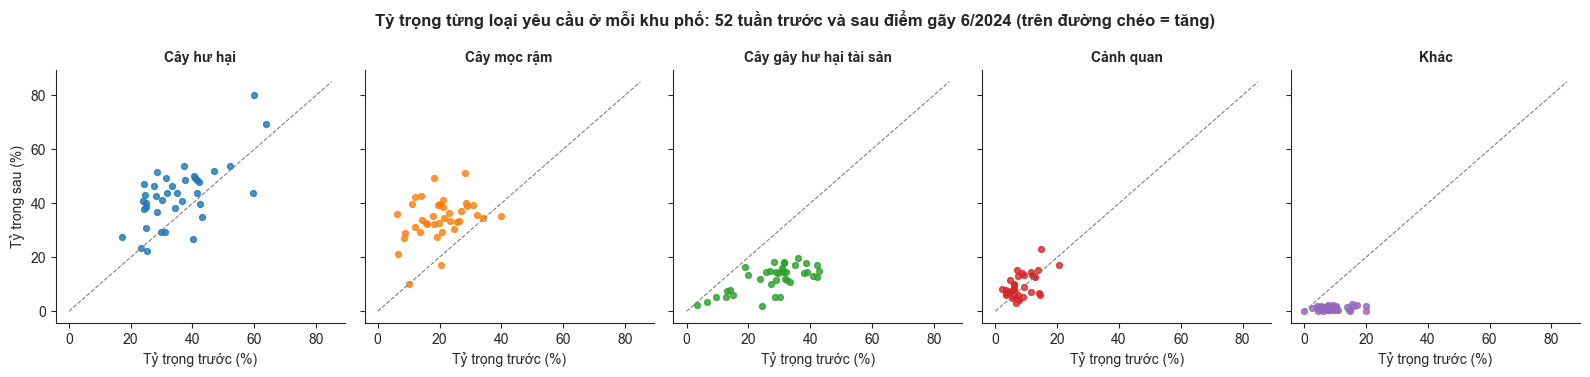

In [7]:
# Biểu đồ: tỷ trọng từng loại ở mỗi khu phố, trước và sau điểm gãy (mỗi điểm là một khu phố)
fig, axes = plt.subplots(1, 5, figsize=(16, 3.8), sharex=True, sharey=True)
for ax, loai in zip(axes, LOAI):
    ax.scatter(tt_truoc.loc[du, loai] * 100, tt_sau.loc[du, loai] * 100, s=18, color=MAU_LOAI[loai], alpha=0.8)
    ax.plot([0, 85], [0, 85], color="gray", linestyle="--", linewidth=0.8)
    ax.set_title(TEN_LOAI[loai], fontsize=10, fontweight="bold")
    ax.set_xlabel("Tỷ trọng trước (%)")
    sns.despine(ax=ax)
axes[0].set_ylabel("Tỷ trọng sau (%)")
fig.suptitle("Tỷ trọng từng loại yêu cầu ở mỗi khu phố: 52 tuần trước và sau điểm gãy 6/2024 (trên đường chéo = tăng)",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("../Outputs/figures/fig_r03_type_share_by_nbhd.png", dpi=300)
plt.show()

**Nhận xét:** Điểm gãy ở từng khu phố

**Vì sao làm bước này?** Nếu cơ cấu chỉ đổi ở vài khu phố, nguyên nhân có thể là sự kiện cục bộ; nếu đổi **cùng hướng ở gần như mọi khu phố** trong khi thứ hạng nhu cầu giữa các khu không đổi, đó là dấu hiệu của **thay đổi cách ghi nhận trên toàn hệ thống**. Mỗi điểm trên biểu đồ là một khu phố; điểm nằm trên đường chéo là khu phố có tỷ trọng loại đó tăng sau điểm gãy.

**Kết quả cần đọc:**
- Xét 38 khu phố đủ số liệu: **"Cây gây hư hại tài sản" giảm ở cả 38/38 khu phố** (trung vị từ 29.9% xuống 13.8%), **"Khác" giảm ở 37/38** (7.7% → 1.3%; khu còn lại không có yêu cầu "Khác" ở cả hai giai đoạn), còn **"Cây mọc rậm" tăng ở 35/38** (20.1% → 34.6%).
- Thứ hạng tổng số yêu cầu giữa các khu phố **gần như giữ nguyên** (Spearman **0.958**); tổng số yêu cầu của mỗi khu chỉ thay đổi vừa phải (trung vị gấp **1.04** lần).
- → Điểm gãy là **thay đổi cách phân loại trên toàn hệ thống**, không phải do nhu cầu ở một vài khu phố thay đổi.

## **5. Yêu cầu trùng trước và sau điểm gãy**

Hệ thống mới cũng có thể thay đổi cách **đánh dấu yêu cầu trùng**. Nếu tỷ lệ trùng thay đổi, hai phiên bản biến mục tiêu (`n` đã loại trùng và `n_all` giữ cả trùng) sẽ khác nhau nhiều hơn sau điểm gãy.

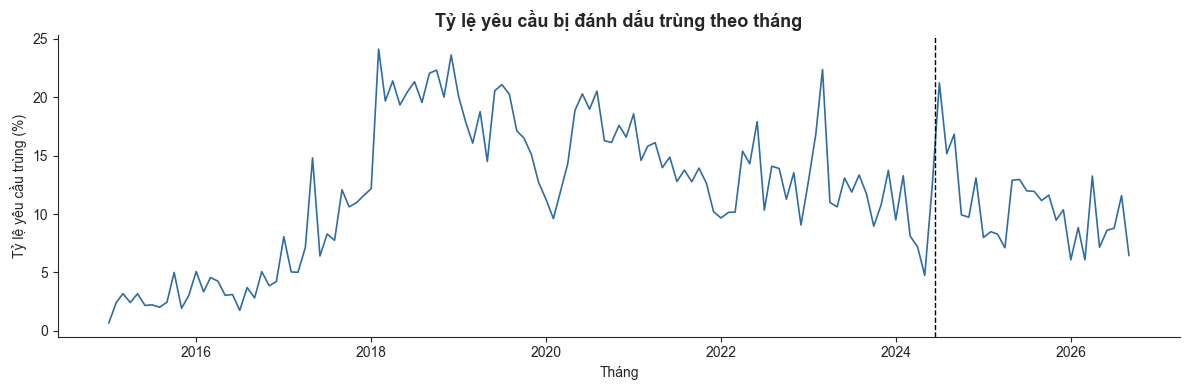

,giai_doan,so_yeu_cau,ty_le_trung_%
0,Toàn bộ 2015-2026,132196,12.2
1,52 tuần trước điểm gãy,11358,10.6
2,52 tuần sau điểm gãy,12529,12.2


In [8]:
# Tỷ lệ yêu cầu bị đánh dấu trùng theo tháng (dùng toàn bộ yêu cầu, kể cả trùng)
thang = cases_all.groupby(cases_all["date"].dt.to_period("M"))["la_trung"].mean() * 100
thang = thang.loc["2015-01": "2026-09"]

plt.figure(figsize=(12, 4))
plt.plot(thang.index.to_timestamp(), thang.values, color="#2E6DA4", linewidth=1.2)
plt.axvline(NGAY_DOI_HE_THONG, color="black", linestyle="--", linewidth=1)
sns.despine()
plt.xlabel("Tháng")
plt.ylabel("Tỷ lệ yêu cầu trùng (%)")
plt.title("Tỷ lệ yêu cầu bị đánh dấu trùng theo tháng", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../Outputs/figures/fig_r04_duplicate_share.png", dpi=300)
plt.show()

truoc_all = cases_all[(cases_all["week_start"] >= TUAN_DOI - pd.Timedelta(weeks=52)) & (cases_all["week_start"] < TUAN_DOI)]
sau_all = cases_all[(cases_all["week_start"] >= TUAN_DOI) & (cases_all["week_start"] < TUAN_DOI + pd.Timedelta(weeks=52))]
trung_df = pd.DataFrame({
    "giai_doan": ["Toàn bộ 2015-2026", "52 tuần trước điểm gãy", "52 tuần sau điểm gãy"],
    "so_yeu_cau": [len(cases_all), len(truoc_all), len(sau_all)],
    "ty_le_trung_%": [round(cases_all["la_trung"].mean() * 100, 1),
                      round(truoc_all["la_trung"].mean() * 100, 1),
                      round(sau_all["la_trung"].mean() * 100, 1)],
})
trung_df

**Nhận xét:** Yêu cầu trùng trước và sau điểm gãy

**Vì sao làm bước này?** Biến mục tiêu chính `n` đã loại yêu cầu trùng, nhưng nhãn trùng chỉ có sau khi yêu cầu được xử lý (Notebook 1, mục 5). Nếu hệ thống mới đánh dấu trùng theo cách khác, độ chênh giữa `n` và `n_all` sẽ đổi theo — đây là lý do Notebook 7 báo cáo kết quả trên cả hai phiên bản.

**Kết quả cần đọc:**
- Tỷ lệ yêu cầu trùng trong 52 tuần **sau** điểm gãy (**12.2%**) chỉ cao hơn 52 tuần **trước** (**10.6%**) khoảng 1.6 điểm %, và bằng đúng mức trung bình của cả giai đoạn 2015–2026 (**12.2%**).
- Ngay sau khi đổi hệ thống có **một tháng tăng vọt** (khoảng 21%), sau đó trở lại mức **6–13%** như trước — giống một giai đoạn chuyển tiếp ngắn khi xử lý tồn đọng, không phải thay đổi lâu dài.
- Thay đổi lớn nhất về yêu cầu trùng xảy ra **sớm hơn nhiều, khoảng 2017–2018**: tỷ lệ tăng từ dưới 5% lên khoảng **20%** và giữ ở mức cao đến 2020 — trùng thời điểm áp dụng **Prop-E**, khi nhiều yêu cầu được gộp vào kế hoạch cắt tỉa theo tuyến phố (đã thấy trong ghi chú 311 ở Notebook 2).
- → Điểm gãy tháng 6/2024 **gần như không làm đổi cách đánh dấu trùng**, nên khác biệt giữa `n` và `n_all` sau 2024 chủ yếu giống như trước; kết quả trên `n_all` ở Notebook 7 dùng để kiểm tra lại, không phải để phát hiện thêm một điểm gãy khác.

## **6. Phân loại các mốc kiểm tra theo điểm gãy**

Notebook 7 đánh giá mô hình ở 9 mốc kiểm tra (Notebook 1, mục 7), mỗi mốc 26 tuần. Bảng dưới xác định mỗi mốc nằm **trước**, **chứa** hay nằm **sau** điểm gãy, cùng mức nhu cầu trung bình của đoạn kiểm tra, để Notebook 7 so sánh độ chính xác theo từng giai đoạn (RQ3).

In [9]:
MOC_KIEM_TRA = ["2022-01-03", "2022-07-04", "2023-01-02", "2023-07-03", "2024-01-01",
                "2024-07-01", "2025-01-06", "2025-07-07", "2026-01-05"]

rows = []
for moc in MOC_KIEM_TRA:
    bat_dau = pd.Timestamp(moc)
    ket_thuc = bat_dau + pd.Timedelta(weeks=26)          # tuần đầu tiên KHÔNG thuộc đoạn kiểm tra
    doan = city_type[(city_type.index >= bat_dau) & (city_type.index < ket_thuc)]
    if ket_thuc <= TUAN_DOI:
        giai_doan = "Trước điểm gãy"
    elif bat_dau <= TUAN_DOI:
        giai_doan = "Chứa điểm gãy"
    else:
        giai_doan = "Sau điểm gãy"
    rows.append({
        "moc_kiem_tra": moc,
        "tuan_cuoi": (ket_thuc - pd.Timedelta(weeks=1)).date(),
        "so_tuan": len(doan),
        "giai_doan": giai_doan,
        "tb_yeu_cau_moi_tuan": round(doan["tong"].mean(), 1),
        "tb_cay_hu_hai_moi_tuan": round(doan["damaged_tree"].mean(), 1),
    })
moc_df = pd.DataFrame(rows)
moc_df

,moc_kiem_tra,tuan_cuoi,so_tuan,giai_doan,tb_yeu_cau_moi_tuan,tb_cay_hu_hai_moi_tuan
0,2022-01-03,2022-06-27,26,Trước điểm gãy,171.0,62.6
1,2022-07-04,2022-12-26,26,Trước điểm gãy,117.4,38.9
2,2023-01-02,2023-06-26,26,Trước điểm gãy,223.1,106.2
3,2023-07-03,2023-12-25,26,Trước điểm gãy,188.2,51.0
4,2024-01-01,2024-06-24,26,Chứa điểm gãy,199.9,84.1
5,2024-07-01,2024-12-23,26,Sau điểm gãy,202.2,84.7
6,2025-01-06,2025-06-30,26,Sau điểm gãy,241.1,93.8
7,2025-07-07,2025-12-29,26,Sau điểm gãy,304.6,88.8
8,2026-01-05,2026-06-29,26,Sau điểm gãy,294.8,85.3


**Nhận xét:** Các mốc kiểm tra theo giai đoạn

**Vì sao làm bước này?** Để trả lời RQ3 (mô hình chịu tác động của điểm gãy ra sao), sai số ở Notebook 7 được gộp theo ba giai đoạn trong bảng này, thay vì chỉ lấy trung bình chung của cả 9 mốc.

**Kết quả cần đọc:**
- **4 mốc trước điểm gãy** (2022–2023), **1 mốc chứa điểm gãy** (01/01/2024) và **4 mốc sau điểm gãy** (từ 01/07/2024); mỗi mốc đủ 26 tuần.
- Nhu cầu trung bình tăng mạnh ở **2 mốc cuối** (khoảng **295–305 yêu cầu/tuần**, so với **117–223** ở các mốc trước), đúng giai đoạn "Cảnh quan" tăng vọt ở mục 2–3 — đây là thử thách lớn nhất cho các mô hình học từ dữ liệu cũ.
- Riêng "Cây hư hại" thì ổn định hơn nhiều: khoảng **84–94 yêu cầu/tuần** ở cả 5 mốc từ 2024, nằm trong khoảng dao động của các mốc trước (39–106).

## **7. Xuất bảng kết quả**

In [10]:
quy.to_csv("../Outputs/tables/regime_01_quarterly_by_type.csv")
nam.to_csv("../Outputs/tables/regime_02_year_over_year.csv")
khu_pho_df.to_csv("../Outputs/tables/regime_03_type_share_by_nbhd.csv", index=False)
trung_df.to_csv("../Outputs/tables/regime_04_duplicate_share.csv", index=False)
moc_df.to_csv("../Outputs/tables/regime_05_test_origins.csv", index=False)

print("Đã lưu xong 4 biểu đồ và 5 bảng kết quả.")

Đã lưu xong 4 biểu đồ và 5 bảng kết quả.


## **Tóm tắt**

- **RQ1:** Đổi bộ phân loại tháng 6/2024 làm **cơ cấu loại yêu cầu thay đổi mạnh nhất trong 11 năm** (gần gấp đôi mức lớn nhất trước đó), xảy ra **đồng loạt ở mọi khu phố**, nhưng **tổng số yêu cầu gần như không đổi**. Mức tăng mạnh của tổng số yêu cầu đến **gần một năm sau**, tập trung ở loại "Cảnh quan".
- **RQ3:** Các mô hình dự báo tổng số yêu cầu (`n`) vì vậy phải đối mặt chủ yếu với **mức tăng đột ngột từ giữa 2025**; biến `n_damaged` ổn định hơn và được dùng làm phép thử bổ sung. Notebook 7 so sánh sai số của từng họ mô hình theo ba giai đoạn ở mục 6.